## Ames House Price Analysis

#### Library And Dataset İmport

In [172]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
housing=pd.read_csv("AmesHousing.csv")

# veriyi istediğim sütunda göstermesini ayarlıyorum.
pd.set_option("display.max_columns",30)

In [173]:
housing.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,...,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,...,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


#### Train-Test Split

In [174]:
# Özellikleri (X) ve hedefi belirlyelim.
X=housing.drop(columns=["SalePrice"])  # matrsi olduğu için x i büyük al
y=housing["SalePrice"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [175]:
# EDA için sadece train verilerini birleştir.Az önce ayırdık çünkü.
train_df=X_train.copy() #referans değil direk kopya aldık veri sızıntısı olmasın diye.
train_df["SalePrice"]=y_train

#boyutları kontrol
print("Train özellikleri:", X_train.shape)
print("Test özellikleri :", X_test.shape)
print("Train EDA tablosu:", train_df.shape)



Train özellikleri: (2344, 81)
Test özellikleri : (586, 81)
Train EDA tablosu: (2344, 82)


#### Exploratory Data Analysis (EDA)

In [176]:
train_df.shape

(2344, 82)

In [177]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2344 entries, 381 to 860
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2344 non-null   int64  
 1   PID              2344 non-null   int64  
 2   MS SubClass      2344 non-null   int64  
 3   MS Zoning        2344 non-null   object 
 4   Lot Frontage     1951 non-null   float64
 5   Lot Area         2344 non-null   int64  
 6   Street           2344 non-null   object 
 7   Alley            162 non-null    object 
 8   Lot Shape        2344 non-null   object 
 9   Land Contour     2344 non-null   object 
 10  Utilities        2344 non-null   object 
 11  Lot Config       2344 non-null   object 
 12  Land Slope       2344 non-null   object 
 13  Neighborhood     2344 non-null   object 
 14  Condition 1      2344 non-null   object 
 15  Condition 2      2344 non-null   object 
 16  Bldg Type        2344 non-null   object 
 17  House Style      2

In [178]:
train_df.describe()

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,...,TotRms AbvGrd,Fireplaces,Garage Yr Blt,Garage Cars,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2344.000000,2.344000e+03,2344.000000,1951.000000,2344.000000,2344.00000,2344.000000,2344.000000,2344.000000,2325.000000,2343.000000,2343.000000,2343.000000,2343.000000,2344.000000,...,2344.000000,2344.000000,2222.00000,2343.000000,2343.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000
mean,1464.298635,7.143632e+08,57.308020,69.207586,10127.857509,6.06442,5.581911,1970.506826,1983.923635,98.539785,442.531370,50.097311,554.393513,1047.022194,1154.814420,...,6.409130,0.598976,1977.39829,1.746906,469.078959,94.113055,47.341724,24.731655,2.422782,16.010239,2.582765,58.055034,6.184727,2007.794795,178582.207765
std,842.982263,1.886907e+08,42.802555,23.418018,8050.908132,1.38852,1.105659,30.341434,20.786287,172.239113,452.223224,170.396999,433.788333,436.567117,385.114269,...,1.563651,0.652987,25.67911,0.746445,212.432786,124.851870,68.037465,67.030943,24.524362,55.820882,38.324145,623.375121,2.708408,1.315117,77125.072713
min,1.000000,5.263011e+08,20.000000,21.000000,1300.000000,1.00000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,...,2.000000,0.000000,1895.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,737.750000,5.284821e+08,20.000000,58.000000,7466.500000,5.00000,5.000000,1953.000000,1965.000000,0.000000,0.000000,0.000000,218.000000,784.000000,879.750000,...,5.000000,0.000000,1960.00000,1.000000,319.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129000.000000
50%,1466.000000,5.354541e+08,50.000000,68.000000,9356.500000,6.00000,5.000000,1972.000000,1992.000000,0.000000,375.000000,0.000000,462.000000,988.000000,1082.000000,...,6.000000,1.000000,1978.00000,2.000000,476.000000,0.000000,26.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2195.250000,9.071921e+08,70.000000,80.000000,11484.250000,7.00000,6.000000,2000.000000,2003.000000,160.000000,734.000000,0.000000,795.500000,1288.000000,1378.000000,...,7.000000,1.000000,2001.00000,2.000000,576.000000,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,210000.000000
max,2930.000000,9.241520e+08,190.000000,313.000000,215245.000000,10.00000,9.000000,2010.000000,2010.000000,1290.000000,5644.000000,1526.000000,2336.000000,6110.000000,5095.000000,...,15.000000,4.000000,2207.00000,4.000000,1488.000000,870.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


In [179]:
train_df["SalePrice"].value_counts()

SalePrice
140000    28
145000    25
135000    25
155000    24
130000    24
160000    19
190000    18
115000    18
185000    18
125000    18
110000    18
170000    17
150000    16
120000    16
127000    16
180000    16
137000    15
200000    15
139000    14
128000    14
119000    13
165000    13
143000    13
175000    13
105000    12
176000    12
146000    12
220000    12
129000    12
144000    12
100000    11
173000    11
250000    11
148000    11
215000    11
153000    11
147000    10
132000    10
178000    10
205000    10
260000    10
108000    10
152000    10
230000    10
158000    10
124000    10
174000     9
184000     9
123000     9
149900     9
240000     9
149000     9
225000     9
127500     9
157500     8
133000     8
85000      8
113000     8
290000     8
181000     8
138000     8
157000     8
136000     8
122000     8
131000     8
235000     8
275000     8
192000     8
112000     8
172500     8
141000     8
159000     7
142000     7
169000     7
137500     7
132500     7
13

In [180]:
train_df["SalePrice"].nunique()

887

In [181]:
# eksik değerleri yüksekten sırala ve yüzdeliğini göster.

eksik = train_df.isnull().sum().sort_values(ascending=False)
eksik_yuzde = (eksik / len(housing) * 100).round(1)
eksik_tablo = pd.DataFrame({"eksik_sayi": eksik, "yuzde": eksik_yuzde})
print(eksik_tablo.head(30))

                eksik_sayi  yuzde
Pool QC               2332   79.6
Misc Feature          2250   76.8
Alley                 2182   74.5
Fence                 1874   64.0
Mas Vnr Type          1426   48.7
Fireplace Qu          1144   39.0
Lot Frontage           393   13.4
Garage Qual            122    4.2
Garage Cond            122    4.2
Garage Finish          122    4.2
Garage Yr Blt          122    4.2
Garage Type            120    4.1
Bsmt Exposure           63    2.2
BsmtFin Type 2          62    2.1
BsmtFin Type 1          61    2.1
Bsmt Cond               61    2.1
Bsmt Qual               61    2.1
Mas Vnr Area            19    0.6
BsmtFin SF 1             1    0.0
Bsmt Full Bath           1    0.0
BsmtFin SF 2             1    0.0
Bsmt Unf SF              1    0.0
Total Bsmt SF            1    0.0
Bsmt Half Bath           1    0.0
Garage Cars              1    0.0
Garage Area              1    0.0
Mo Sold                  0    0.0
Full Bath                0    0.0
Half Bath     

#### Target Analysis (EDA)

In [182]:
train_df["SalePrice"].describe()

count      2344.000000
mean     178582.207765
std       77125.072713
min       12789.000000
25%      129000.000000
50%      160000.000000
75%      210000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [183]:
print("Skewness",train_df["SalePrice"].skew()) #skew 0a yakınsa simetrik, > 1 ise güçlü sağa çarpık.
print("Kurtosis:", train_df['SalePrice'].kurt()) # kurt: yüksekse kuyruklar ağır (çok uç değer var).

Skewness 1.7505967618875342
Kurtosis: 5.474454514928182


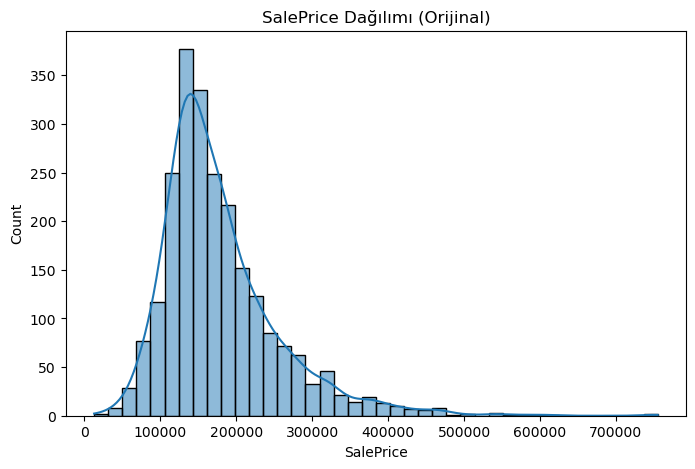

In [184]:

plt.figure(figsize=(8, 5))
sns.histplot(train_df['SalePrice'], kde=True, bins=40)
plt.title('SalePrice Dağılımı (Orijinal)')
plt.xlabel('SalePrice')
plt.show()

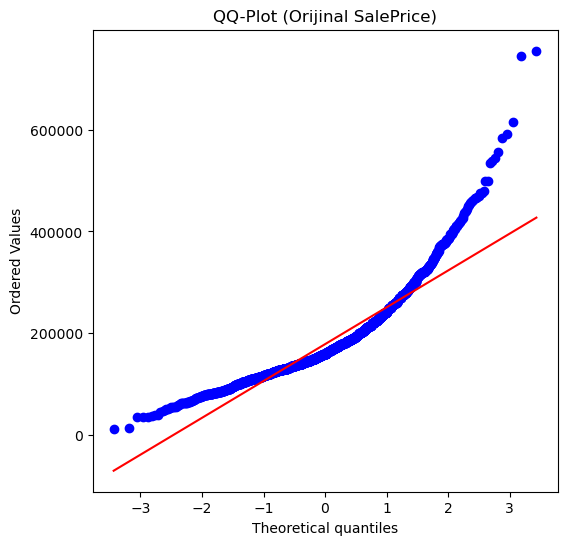

In [185]:
from scipy import stats
plt.figure(figsize=(6, 6))
stats.probplot(train_df['SalePrice'], dist="norm", plot=plt)
plt.title('QQ-Plot (Orijinal SalePrice)')
plt.show()

In [186]:
# Yeni sütun olarak ekle, orijinali bozma
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

print("Log sonrası Skewness:", train_df['SalePrice_log'].skew())
print("Log sonrası Kurtosis:", train_df['SalePrice_log'].kurt())

Log sonrası Skewness: -0.09069864066048615
Log sonrası Kurtosis: 1.8976905944449194


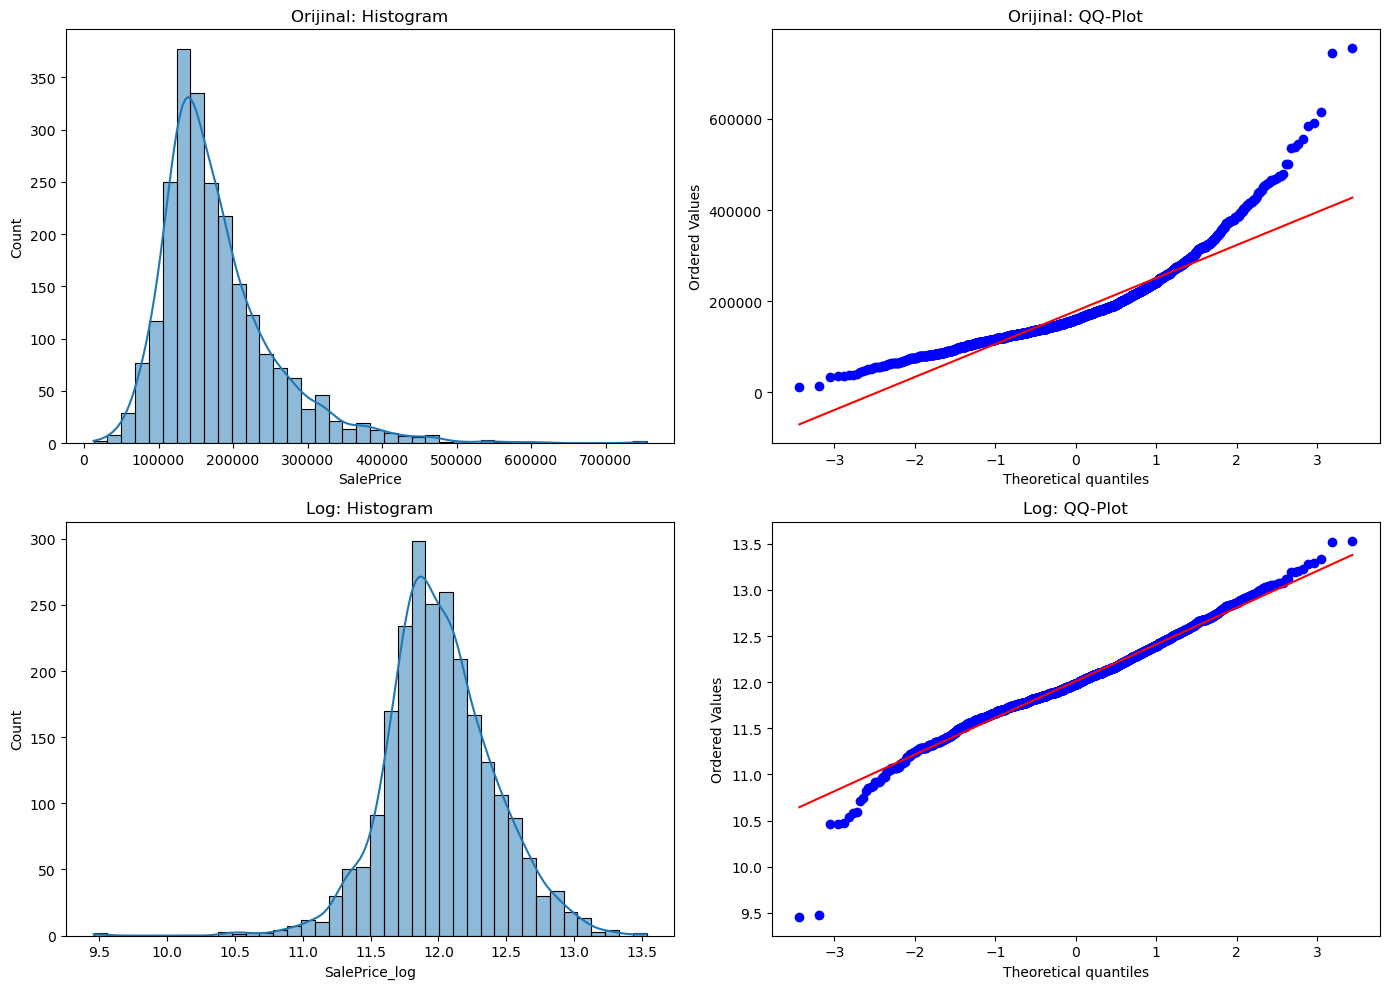

In [187]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Orijinal: histogram
sns.histplot(train_df['SalePrice'], kde=True, bins=40, ax=axes[0, 0])
axes[0, 0].set_title('Orijinal: Histogram')

# Orijinal: QQ
stats.probplot(train_df['SalePrice'], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Orijinal: QQ-Plot')

# Log: histogram
sns.histplot(train_df['SalePrice_log'], kde=True, bins=40, ax=axes[1, 0])
axes[1, 0].set_title('Log: Histogram')

# Log: QQ
stats.probplot(train_df['SalePrice_log'], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Log: QQ-Plot')

plt.tight_layout()
plt.show()

#### Missing Value Analysis (EDA)

In [188]:
missing = X_train.isnull().sum()
missing_pct = (missing / len(X_train)) * 100

missing_df = pd.DataFrame({
    'Eksik_Sayi': missing,
    'Eksik_Yuzde': missing_pct.round(2),
    'Tip': X_train.dtypes
})

missing_df = missing_df[missing_df['Eksik_Sayi'] > 0].sort_values('Eksik_Sayi', ascending=False)
print(missing_df)
print("\nEksik değeri olan sütun sayısı:", len(missing_df))

                Eksik_Sayi  Eksik_Yuzde      Tip
Pool QC               2332        99.49   object
Misc Feature          2250        95.99   object
Alley                 2182        93.09   object
Fence                 1874        79.95   object
Mas Vnr Type          1426        60.84   object
Fireplace Qu          1144        48.81   object
Lot Frontage           393        16.77  float64
Garage Yr Blt          122         5.20  float64
Garage Cond            122         5.20   object
Garage Qual            122         5.20   object
Garage Finish          122         5.20   object
Garage Type            120         5.12   object
Bsmt Exposure           63         2.69   object
BsmtFin Type 2          62         2.65   object
Bsmt Qual               61         2.60   object
BsmtFin Type 1          61         2.60   object
Bsmt Cond               61         2.60   object
Mas Vnr Area            19         0.81  float64
BsmtFin SF 1             1         0.04  float64
Bsmt Half Bath      

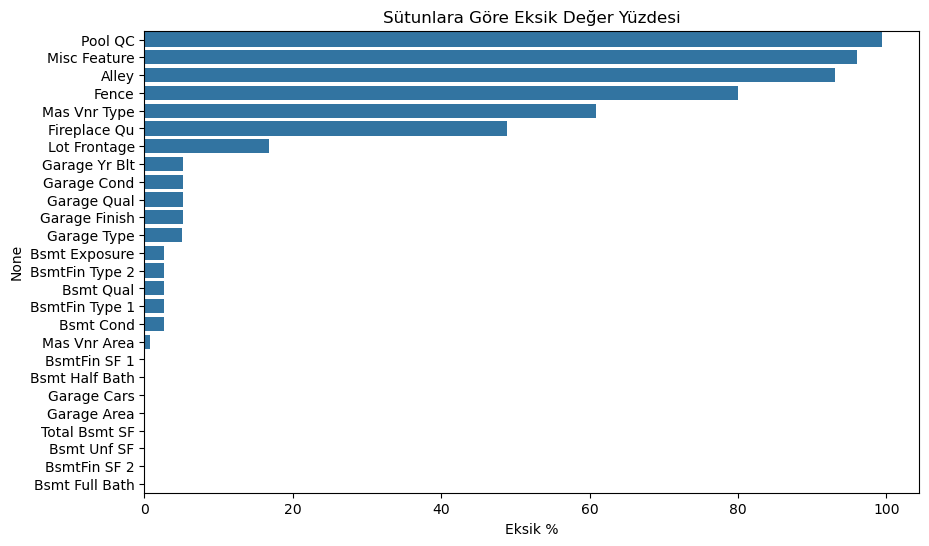

In [189]:
plt.figure(figsize=(10, 6))
sns.barplot(x=missing_df['Eksik_Yuzde'], y=missing_df.index)
plt.title('Sütunlara Göre Eksik Değer Yüzdesi')
plt.xlabel('Eksik %')
plt.show()

In [190]:
#NaN teknik olarak hep "değer yok" der ama anlamı ikiye ayrılır — "bilinmiyor/ölçülmedi" 
# (gerçek eksik veri → medyan/mod ile doldurulur) ya da "o özellik zaten mevcut değil" (yapısal yokluk → None/0 ile doldurulur);
#  Ames Housing'te ikincisi baskındır.

# Kategorik: NaN = "özellik yok" -> "None" ile doldurulacak
cat_none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType']


# Sayısal: NaN = "özellik yok" -> 0 ile doldurulacak
num_zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

In [191]:
# sıfır ve none ladıklarımızın dışındaki kalan boş girdi olan sütunlar

#boşluklu olanları birleştir.
missing_df.index = missing_df.index.str.replace(' ', '')

handled = set(cat_none_cols + num_zero_cols)
remaining = [c for c in missing_df.index if c not in handled]
print("Kalan eksikli sütunlar:", remaining)

Kalan eksikli sütunlar: ['LotFrontage']


In [192]:
missing_lotfrontage=train_df["Lot Frontage"].isnull().sum()
yuzde_lotfrontage=(missing_lotfrontage/len(train_df)) *100
print("Lot Frontage missing analysis \nEksik:",missing_lotfrontage,"\nYuzde:",yuzde_lotfrontage)

Lot Frontage missing analysis 
Eksik: 393 
Yuzde: 16.766211604095563


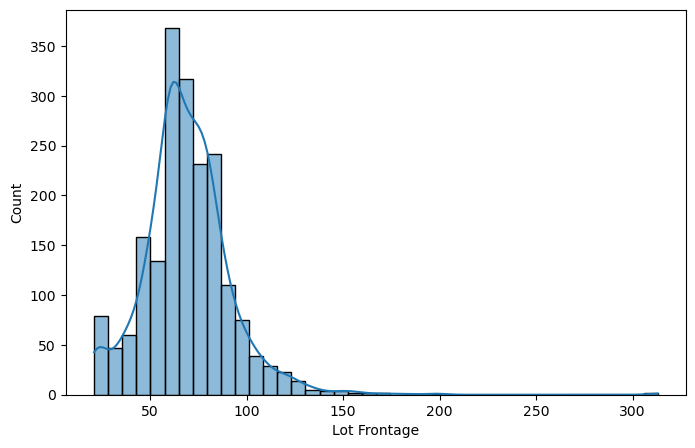

In [193]:

plt.figure(figsize=(8, 5))
sns.histplot(train_df['Lot Frontage'], kde=True, bins=40)
plt.show()

In [194]:
# Hangi değerin kaç kere geçtiği
pd.set_option('display.max_rows', None) 
train_df["Lot Frontage"].value_counts()
# ayarı kapatmak istersen sonra  "pd.set_option('display.max_rows', None)"

Lot Frontage
60.0     222
70.0     111
80.0     110
50.0      92
75.0      81
65.0      75
85.0      57
90.0      39
24.0      39
78.0      38
68.0      38
21.0      36
64.0      35
74.0      31
63.0      29
72.0      27
79.0      26
62.0      26
59.0      24
73.0      23
82.0      23
57.0      22
51.0      22
53.0      22
76.0      21
88.0      21
55.0      21
100.0     21
66.0      21
52.0      20
43.0      18
40.0      18
67.0      17
56.0      17
58.0      16
81.0      16
61.0      16
35.0      15
44.0      14
69.0      14
84.0      14
34.0      14
71.0      14
95.0      13
48.0      13
120.0     13
83.0      12
110.0     12
96.0      12
93.0      12
77.0      12
91.0      11
86.0      10
92.0      10
98.0      10
54.0      10
42.0      10
41.0      10
87.0       9
102.0      9
89.0       8
94.0       8
105.0      8
45.0       8
30.0       8
36.0       7
39.0       6
99.0       6
32.0       6
37.0       6
47.0       6
103.0      5
107.0      5
114.0      5
109.0      4
49.0       4

In [195]:
print("nunique:",train_df["Lot Frontage"].nunique())
train_df["Lot Frontage"].describe()

nunique: 120


count    1951.000000
mean       69.207586
std        23.418018
min        21.000000
25%        58.000000
50%        68.000000
75%        80.000000
max       313.000000
Name: Lot Frontage, dtype: float64

In [196]:
train_df.groupby("Neighborhood")["Lot Frontage"].median()

Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.5
CollgCr    70.0
Crawfor    66.0
Edwards    65.0
Gilbert    63.0
Greens     40.0
GrnHill     NaN
IDOTRR     60.0
Landmrk     NaN
MeadowV    21.0
Mitchel    71.0
NAmes      74.0
NPkVill    24.0
NWAmes     80.0
NoRidge    85.0
NridgHt    90.0
OldTown    60.0
SWISU      60.0
Sawyer     72.0
SawyerW    67.0
Somerst    72.0
StoneBr    59.5
Timber     80.0
Veenker    80.0
Name: Lot Frontage, dtype: float64

In [197]:
# 1) Yapısal yokluklar test veriisndeki nan değerlerine işlem uygulanır train istatistikleriyle maksat veri sızıntısı olmasın.
test_df = X_test

# sütun isimlerindeki boşluğu kaldır
train_df.columns = train_df.columns.str.replace(' ', '')
test_df.columns  = test_df.columns.str.replace(' ', '')

# nanları doldur
for col in cat_none_cols:
    train_df[col] = train_df[col].fillna('None')
    test_df[col]  = test_df[col].fillna('None')

for col in num_zero_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col]  = test_df[col].fillna(0)


# 2) LotFrontage: caddeye uzunluğu bir genel medyan al birde komşuya göre mahalleye göre  (train'den öğren)
nbhd_median = train_df.groupby('Neighborhood')['LotFrontage'].median()
global_median = train_df['LotFrontage'].median()

train_df['LotFrontage'] = train_df['LotFrontage'].fillna(
    train_df['Neighborhood'].map(nbhd_median) # burada map neighborhood değişkeninin yerine median değerini kouyor geçiic olarak
).fillna(global_median)

# traine uyguladığımı teste de uyguluyorum.
test_df['LotFrontage'] = test_df['LotFrontage'].fillna(
    test_df['Neighborhood'].map(nbhd_median)      # aynı nbhd_median
).fillna(global_median)

In [198]:
train_df.isnull().sum() # doğrulama başarılı

Order            0
PID              0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
Alley            0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemod/Add    0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr